# Robustness Analysis

Evaluate model behavior under input perturbations.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import models, transforms
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Robustness testing imports completed!")
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

Robustness testing imports completed!
Device: cpu


In [3]:

# Load the existing test split
test_df = pd.read_csv("../data/metadata/test_split.csv")

# Locate the MHIST images
image_dir = os.path.abspath("../data/raw/images/images")

print("Test images:", len(test_df))
print("Image folder exists:", os.path.isdir(image_dir))
print("Test labels:")
print(test_df["Majority Vote Label"].value_counts())


Test images: 977
Image folder exists: True
Test labels:
Majority Vote Label
HP     617
SSA    360
Name: count, dtype: int64


In [4]:

from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Standard preprocessing used by the pretrained model
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

class RobustnessDataset(Dataset):
    def __init__(self, dataframe, image_dir, condition="original"):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.condition = condition

        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = os.path.join(
            self.image_dir, row["Image Name"]
        )
        image = Image.open(image_path).convert("RGB")

        # Apply one controlled image alteration
        if self.condition == "low_brightness":
            image = transforms.functional.adjust_brightness(
                image, 0.6
            )

        elif self.condition == "low_contrast":
            image = transforms.functional.adjust_contrast(
                image, 0.6
            )

        image_tensor = self.to_tensor(image)

        if self.condition == "gaussian_noise":
            torch.manual_seed(index)
            noise = torch.randn_like(image_tensor) * 0.05
            image_tensor = torch.clamp(
                image_tensor + noise, 0, 1
            )

        image_tensor = normalize(image_tensor)

        label = 0 if row["Majority Vote Label"] == "HP" else 1

        return image_tensor, torch.tensor(label, dtype=torch.long)


print("Robustness dataset class created!")


Robustness dataset class created!


In [5]:

conditions = [
    "original",
    "low_brightness",
    "low_contrast",
    "gaussian_noise"
]

robustness_loaders = {}

for condition in conditions:
    dataset = RobustnessDataset(
        test_df,
        image_dir,
        condition=condition
    )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0
    )

    robustness_loaders[condition] = loader

    print(
        f"{condition}: "
        f"{len(dataset)} images, {len(loader)} batches"
    )

print("\nAll robustness DataLoaders created successfully!")


original: 977 images, 31 batches
low_brightness: 977 images, 31 batches
low_contrast: 977 images, 31 batches
gaussian_noise: 977 images, 31 batches

All robustness DataLoaders created successfully!


In [6]:

checkpoint_dir = "../models/checkpoints"

if os.path.isdir(checkpoint_dir):
    checkpoint_files = [
        f for f in os.listdir(checkpoint_dir)
        if f.endswith((".pth", ".pt", ".pth.tar"))
    ]

    print("Saved model checkpoints:", checkpoint_files)

    if not checkpoint_files:
        print("No trained model weights found.")
else:
    print("Checkpoint folder does not exist.")


Saved model checkpoints: []
No trained model weights found.


In [9]:

# Load the trained MobileNetV3-Small model
mobilenet = models.mobilenet_v3_small(weights=None)
mobilenet.classifier[3] = nn.Linear(
    mobilenet.classifier[3].in_features, 2
)

checkpoint_path = "../models/checkpoints/mobilenetv3_small.pth"

mobilenet.load_state_dict(
    torch.load(checkpoint_path, map_location="cpu", weights_only=True)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mobilenet = mobilenet.to(device)
mobilenet.eval()

print("Trained MobileNetV3-Small loaded successfully!")
print("Device:", device)


Trained MobileNetV3-Small loaded successfully!
Device: cpu


In [10]:

results = []

for condition, loader in robustness_loaders.items():
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = mobilenet(images)
            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(
        all_labels, all_predictions, zero_division=0
    )
    recall = recall_score(
        all_labels, all_predictions, zero_division=0
    )
    f1 = f1_score(
        all_labels, all_predictions, zero_division=0
    )

    results.append({
        "Condition": condition,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"{condition}: Accuracy = {accuracy:.4f}")

robustness_df = pd.DataFrame(results)
robustness_df


original: Accuracy = 0.8352
low_brightness: Accuracy = 0.7247
low_contrast: Accuracy = 0.8444
gaussian_noise: Accuracy = 0.7963


,Condition,Accuracy,Precision,Recall,F1 Score
0,original,0.835210,0.890196,0.630556,0.738211
1,low_brightness,0.724667,0.933333,0.272222,0.421505
2,low_contrast,0.844422,0.863636,0.686111,0.764706
3,gaussian_noise,0.796315,0.917098,0.491667,0.640145


In [12]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for condition, loader in robustness_loaders.items():
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = mobilenet(images)
            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    results.append({
        "Condition": condition,
        "Accuracy": accuracy_score(all_labels, all_predictions),
        "Precision": precision_score(
            all_labels, all_predictions, zero_division=0
        ),
        "Recall": recall_score(
            all_labels, all_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            all_labels, all_predictions, zero_division=0
        )
    })

robustness_df = pd.DataFrame(results)

print("Robustness Testing Results")
display(robustness_df.round(4))


Robustness Testing Results


,Condition,Accuracy,Precision,Recall,F1 Score
0,original,0.8352,0.8902,0.6306,0.7382
1,low_brightness,0.7247,0.9333,0.2722,0.4215
2,low_contrast,0.8444,0.8636,0.6861,0.7647
3,gaussian_noise,0.7963,0.9171,0.4917,0.6401


In [13]:

# Save robustness results
output_path = "../results/robustness_results.csv"

robustness_df.to_csv(output_path, index=False)

print("Robustness results saved successfully!")
print("Saved to:", output_path)

display(robustness_df.round(4))


Robustness results saved successfully!
Saved to: ../results/robustness_results.csv


,Condition,Accuracy,Precision,Recall,F1 Score
0,original,0.8352,0.8902,0.6306,0.7382
1,low_brightness,0.7247,0.9333,0.2722,0.4215
2,low_contrast,0.8444,0.8636,0.6861,0.7647
3,gaussian_noise,0.7963,0.9171,0.4917,0.6401


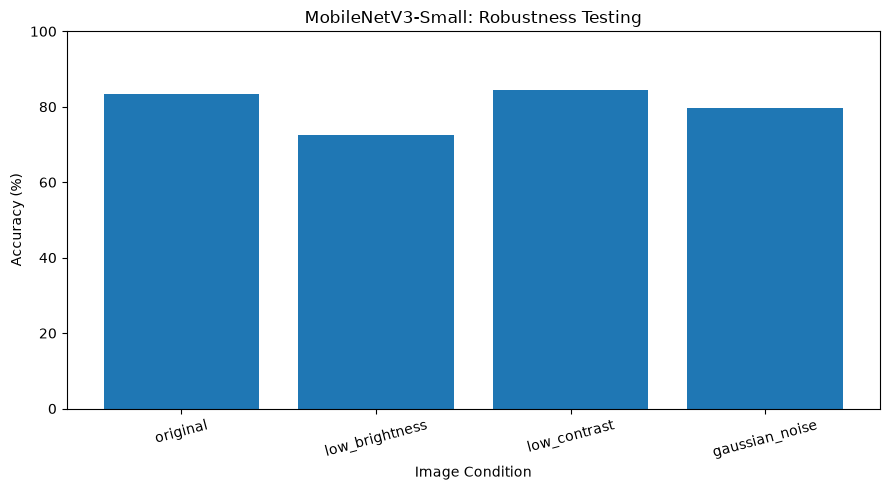

Robustness accuracy plot saved successfully!


In [14]:

plt.figure(figsize=(9, 5))

plt.bar(
    robustness_df["Condition"],
    robustness_df["Accuracy"] * 100
)

plt.title("MobileNetV3-Small: Robustness Testing")
plt.xlabel("Image Condition")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("../results/figures/robustness_accuracy.png", dpi=300)
plt.show()

print("Robustness accuracy plot saved successfully!")


In [15]:

import os

files_to_check = [
    "../results/robustness_results.csv",
    "../results/figures/robustness_accuracy.png",
    "../models/checkpoints/mobilenetv3_small.pth"
]

for file_path in files_to_check:
    print(
        "FOUND" if os.path.exists(file_path) else "MISSING",
        file_path
    )


FOUND ../results/robustness_results.csv
FOUND ../results/figures/robustness_accuracy.png
FOUND ../models/checkpoints/mobilenetv3_small.pth
